Using device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
Epoch  10/120 | Train MSE=0.262026 | Test MSE=0.262041 | EI_full=-15.642216 | dEI=-5.214072
Epoch  20/120 | Train MSE=0.239815 | Test MSE=0.239845 | EI_full=-16.141547 | dEI=-5.380516
Epoch  30/120 | Train MSE=0.227604 | Test MSE=0.227636 | EI_full=-15.897182 | dEI=-5.299061
Epoch  40/120 | Train MSE=0.223053 | Test MSE=0.223081 | EI_full=-15.486829 | dEI=-5.162276
Epoch  50/120 | Train MSE=0.221729 | Test MSE=0.221752 | EI_full=-15.360172 | dEI=-5.120057
Epoch  60/120 | Train MSE=0.221397 | Test MSE=0.221418 | EI_full=-15.294868 | dEI=-5.098289
Epoch  70/120 | Train MSE=0.221301 | Test MSE=0.221321 | EI_full=-15.245023 | dEI=-5.081674
Epoch  80/120 | Train MSE=0.221244 | Test MSE=0.221263 | EI_full=-15.183353 | dEI=-5.061118
Epoch  90/120 | Train MSE=0.221186 | Test MSE=0.221206 | EI_full=-15.169487 | dEI=-5.056496
Epoch 100/120 | Train MSE=0.221125 | Test MSE=0.221146 | EI_full=-15.144164 | dEI=-5.048055
Epoch 110/120 | Train

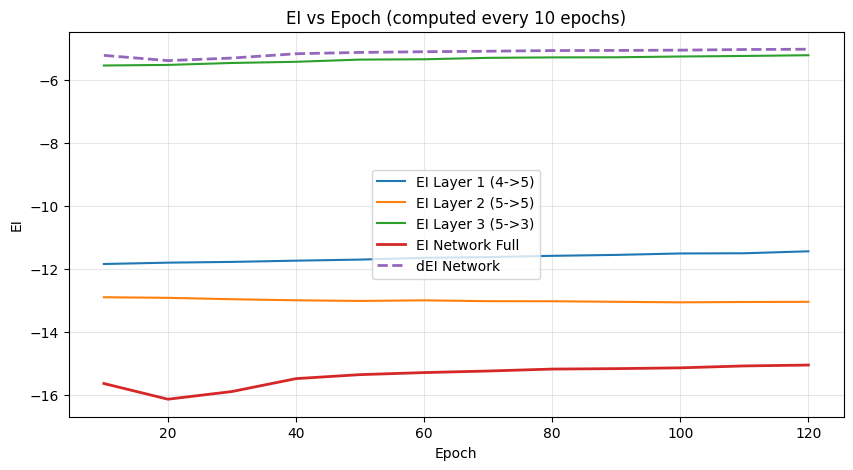

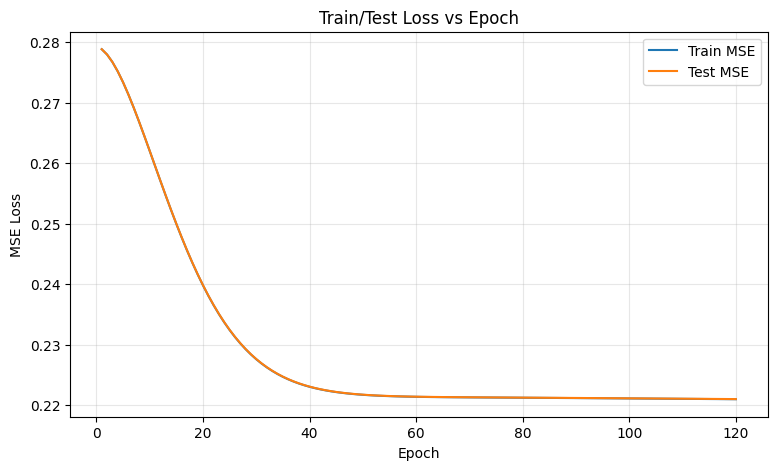


Done.
Device=cuda, L=1.0, N_SAMPLE=200, EPS=1e-12, TEST_SIZE=0.2, LR=0.05, MOMENTUM=0.9, WEIGHT_DECAY=0.0001, EI_EVAL_INTERVAL=10


In [7]:
# Iris baseline: 4->5->5->3, Sigmoid, no bias, MSE + SGD
# EI uses a full-form implementation (with noise term) + a dimension-averaged view.

import math
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# ======================
# 1) 参数（更容易降低 sigma2 的配置）
# ======================
SEED = 42
EPOCHS = 120
LR = 0.05
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-4
L = 1.0
N_SAMPLE = 200
TEST_SIZE = 0.2
EPS = 1e-12
EI_EVAL_INTERVAL = 10  # EI 每 10 个 epoch 计算一次

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# ======================
# 2) 数据准备
# ======================
iris = load_iris()
X = iris.data.astype(np.float32)
y = iris.target.astype(np.int64)

# 缩放到[-1,1]，匹配 U([-L,L]^n)
scaler = MinMaxScaler(feature_range=(-1, 1))
X = scaler.fit_transform(X).astype(np.float32)

Y = np.zeros((len(y), 3), dtype=np.float32)
Y[np.arange(len(y)), y] = 1.0

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)

x_train = torch.tensor(X_train, dtype=torch.float32, device=device)
y_train = torch.tensor(Y_train, dtype=torch.float32, device=device)
x_test = torch.tensor(X_test, dtype=torch.float32, device=device)
y_test = torch.tensor(Y_test, dtype=torch.float32, device=device)

# ======================
# 3) 模型
# ======================
class IrisMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.l1 = nn.Linear(4, 5, bias=False)
        self.l2 = nn.Linear(5, 5, bias=False)
        self.l3 = nn.Linear(5, 3, bias=False)
        self.act = nn.Sigmoid()

    def forward(self, x):
        x = self.act(self.l1(x))
        x = self.act(self.l2(x))
        x = self.act(self.l3(x))
        return x


def init_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.xavier_uniform_(m.weight)


model = IrisMLP().to(device)
model.apply(init_weights)
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(
    model.parameters(), lr=LR, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY
)

@torch.no_grad()
def mse_loss(model, x, y):
    return torch.mean((model(x) - y) ** 2).item()

@torch.no_grad()
def per_dim_mse(model, x, y):
    # sigma_i^2: 每个输出维度的测试集 MSE
    return torch.mean((model(x) - y) ** 2, dim=0).cpu().numpy()


def mean_log_pdet_jacobian(func, in_dim, out_dim, n_samples=1000, L=1.0, eps=1e-12):
    """
    计算 E[log |pdet(J)|]。
    非方阵时使用广义行列式（前 d=min(in_dim,out_dim) 个奇异值乘积）。
    """
    d = min(in_dim, out_dim)
    vals = []

    for _ in range(n_samples):
        x = (torch.rand(in_dim, device=device) * 2 * L - L).requires_grad_(True)

        def f(inp):
            return func(inp.unsqueeze(0)).squeeze(0)

        J = torch.autograd.functional.jacobian(f, x)  # [out_dim, in_dim]
        s = torch.linalg.svdvals(J)
        vals.append(torch.log(torch.abs(s[:d]) + eps).sum().detach())

    return torch.stack(vals).mean().item(), d


def compute_ei_full(sigma2, e_log_pdet, n_in, m_out, L=1.0, eps=1e-12):
    """
    完整 EI：
    EI = n*ln(2L) - (m/2)*(1+ln(2π)) - (1/2)*sum_i ln(sigma_i^2) + E[ln|pdet(J)|]
    """
    sigma2 = np.asarray(sigma2, dtype=np.float64)
    term_range = n_in * math.log(2.0 * L)
    term_const = -0.5 * m_out * (1.0 + math.log(2.0 * math.pi))
    term_noise = -0.5 * float(np.sum(np.log(sigma2 + eps)))
    term_jac = e_log_pdet
    return term_range + term_const + term_noise + term_jac


def compute_dei_from_full(ei_full, d):
    return ei_full / d


def sigma2_from_backprop_loss(loss_value, m_out, eps=1e-12):
    """
    使用当前反向传播的 loss 值作为层间噪声方差 sigma_i^2 的代理。
    所有输出维度共享同一个 sigma^2 估计。
    """
    sigma2_scalar = max(float(loss_value), eps)
    return np.full((m_out,), sigma2_scalar, dtype=np.float64)


# ======================
# 4) 训练 + 记录 EI 与 Loss
# ======================
train_losses, test_losses = [], []

# 网络整体：完整EI + 维度平均EI（每10个epoch记录）
ei_epochs = []
ei_net_full_curve, ei_net_davg_curve = [], []

# 层间EI动态（每10个epoch记录）
ei_l1_curve, ei_l2_curve, ei_l3_curve = [], [], []

for epoch in range(1, EPOCHS + 1):
    model.train()
    optimizer.zero_grad()
    pred = model(x_train)
    loss = criterion(pred, y_train)
    backprop_loss_value = float(loss.detach().item())
    loss.backward()
    optimizer.step()

    model.eval()
    tr_loss = mse_loss(model, x_train, y_train)
    te_loss = mse_loss(model, x_test, y_test)
    train_losses.append(tr_loss)
    test_losses.append(te_loss)

    # EI 每 10 个 epoch 计算一次
    if epoch % EI_EVAL_INTERVAL == 0:
        ei_epochs.append(epoch)

        # ---------- 网络整体 EI（完整公式） ----------
        sigma2 = per_dim_mse(model, x_test, y_test)  # 测试集误差方差

        e_log_pdet_net, d_net = mean_log_pdet_jacobian(
            lambda inp: model(inp), in_dim=4, out_dim=3, n_samples=N_SAMPLE, L=L, eps=EPS
        )

        ei_net_full = compute_ei_full(
            sigma2=sigma2,
            e_log_pdet=e_log_pdet_net,
            n_in=4,
            m_out=3,
            L=L,
            eps=EPS,
        )
        ei_net_full_curve.append(ei_net_full)
        ei_net_davg_curve.append(compute_dei_from_full(ei_net_full, d_net))

        # ---------- 层间 EI 动态（完整公式：sigma 由反传 loss 代理） ----------
        e_log_pdet_l1, _ = mean_log_pdet_jacobian(
            lambda inp: torch.sigmoid(model.l1(inp)), in_dim=4, out_dim=5, n_samples=N_SAMPLE, L=L, eps=EPS
        )
        sigma2_l1 = sigma2_from_backprop_loss(backprop_loss_value, m_out=5, eps=EPS)
        ei_l1 = compute_ei_full(
            sigma2=sigma2_l1,
            e_log_pdet=e_log_pdet_l1,
            n_in=4,
            m_out=5,
            L=L,
            eps=EPS,
        )
        ei_l1_curve.append(ei_l1)

        e_log_pdet_l2, _ = mean_log_pdet_jacobian(
            lambda inp: torch.sigmoid(model.l2(inp)), in_dim=5, out_dim=5, n_samples=N_SAMPLE, L=L, eps=EPS
        )
        sigma2_l2 = sigma2_from_backprop_loss(backprop_loss_value, m_out=5, eps=EPS)
        ei_l2 = compute_ei_full(
            sigma2=sigma2_l2,
            e_log_pdet=e_log_pdet_l2,
            n_in=5,
            m_out=5,
            L=L,
            eps=EPS,
        )
        ei_l2_curve.append(ei_l2)

        e_log_pdet_l3, _ = mean_log_pdet_jacobian(
            lambda inp: torch.sigmoid(model.l3(inp)), in_dim=5, out_dim=3, n_samples=N_SAMPLE, L=L, eps=EPS
        )
        sigma2_l3 = sigma2_from_backprop_loss(backprop_loss_value, m_out=3, eps=EPS)
        ei_l3 = compute_ei_full(
            sigma2=sigma2_l3,
            e_log_pdet=e_log_pdet_l3,
            n_in=5,
            m_out=3,
            L=L,
            eps=EPS,
        )
        ei_l3_curve.append(ei_l3)

        print(
            f"Epoch {epoch:3d}/{EPOCHS} | "
            f"Train MSE={tr_loss:.6f} | Test MSE={te_loss:.6f} | "
            f"EI_full={ei_net_full_curve[-1]:.6f} | dEI={ei_net_davg_curve[-1]:.6f}"
        )

# ======================
# 5) Plot (English labels to avoid CJK font warnings)
# ======================
plt.figure(figsize=(10, 5))
plt.plot(ei_epochs, ei_l1_curve, label="EI Layer 1 (4->5)")
plt.plot(ei_epochs, ei_l2_curve, label="EI Layer 2 (5->5)")
plt.plot(ei_epochs, ei_l3_curve, label="EI Layer 3 (5->3)")
plt.plot(ei_epochs, ei_net_full_curve, label="EI Network Full", linewidth=2)
plt.plot(ei_epochs, ei_net_davg_curve, label="dEI Network", linewidth=2, linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("EI")
plt.title("EI vs Epoch (computed every 10 epochs)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(range(1, EPOCHS + 1), train_losses, label="Train MSE")
plt.plot(range(1, EPOCHS + 1), test_losses, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Train/Test Loss vs Epoch")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("\nDone.")
print(
    f"Device={device}, L={L}, N_SAMPLE={N_SAMPLE}, EPS={EPS}, TEST_SIZE={TEST_SIZE}, "
    f"LR={LR}, MOMENTUM={MOMENTUM}, WEIGHT_DECAY={WEIGHT_DECAY}, EI_EVAL_INTERVAL={EI_EVAL_INTERVAL}"
)